# Solving classification problems with CatBoost

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/catboost/tutorials/blob/master/events/pydata_nyc_oct_19_2018.ipynb)

In this tutorial we will use dataset Amazon Employee Access Challenge from [Kaggle](https://www.kaggle.com) competition for our experiments. Data can be downloaded [here](https://www.kaggle.com/c/amazon-employee-access-challenge/data).

## Libraries installation

In [1]:
#!pip install --user --upgrade catboost
#!pip install --user --upgrade ipywidgets
#!pip install shap
#!pip install sklearn
#!pip install --upgrade numpy
#!pip install --upgrade pandas
#!jupyter nbextension enable --py widgetsnbextension

In [2]:
import catboost
print(catboost.__version__)
!python --version

0.10.2
Python 3.5.5 :: Anaconda custom (64-bit)


## Reading the data

The most simple way — read everything in pandas data frame

In [3]:
import pandas as pd
import os
import numpy as np
np.set_printoptions(precision=4)
import catboost
from catboost import *
from catboost import datasets

In [4]:
# import ssl
# ssl._create_default_https_context = ssl._create_unverified_context

In [5]:
(train_df, test_df) = catboost.datasets.amazon()

In [6]:
train_df.head()

,ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
0,1,39353,85475,117961,118300,123472,117905,117906,290919,117908
1,1,17183,1540,117961,118343,123125,118536,118536,308574,118539
2,1,36724,14457,118219,118220,117884,117879,267952,19721,117880
3,1,36135,5396,117961,118343,119993,118321,240983,290919,118322
4,1,42680,5905,117929,117930,119569,119323,123932,19793,119325


## Preparing your data

Label values extraction

In [7]:
y = train_df.ACTION
X = train_df.drop('ACTION', axis=1)

Categorical features declaration

In [8]:
cat_features = list(range(0, X.shape[1]))
print(cat_features)

[0, 1, 2, 3, 4, 5, 6, 7, 8]


Looking on label balance in dataset

In [9]:
print('Labels: ', set(y))
print('Zero count = ' + str(len(y) - sum(y)) + ', One count = ' + str(sum(y)))

Labels:  {0, 1}
Zero count = 1897, One count = 30872


To train model in CatBoost we need to create wrapper class for data: Pool.
This class stores the data in CatBoost internal format.

There exists several ways to create pool. 
The most simple one: create it from pandas dataframe or numpy array

In [10]:
pool1 = Pool(data=X, 
             label=y,
             cat_features=cat_features) #Indicies of categorical columns in X

This approach is not the most efficient, especially for big dataset: we'll need to copy everything from pandas to our internal format.

So CatBoost could create Pool direclty from file

Lets look how we could load Pool from file

Firstly, lets save data frame to disk

In [11]:
dataset_dir = './amazon'
if not os.path.exists(dataset_dir):
    os.makedirs(dataset_dir)

# We will be able to work with files with/without header and with different separators.
train_df.to_csv(os.path.join(dataset_dir, 'train.tsv'), index=False, sep='\t', header=False)
test_df.to_csv(os.path.join(dataset_dir, 'test.tsv'), index=False, sep='\t', header=False)

train_df.to_csv(os.path.join(dataset_dir, 'train.csv'), index=False, sep=',', header=True)
test_df.to_csv(os.path.join(dataset_dir, 'test.csv'), index=False, sep=',', header=True)

In [12]:
!head -n2 amazon/train.tsv

1	39353	85475	117961	118300	123472	117905	117906	290919	117908
1	17183	1540	117961	118343	123125	118536	118536	308574	118539


In [13]:
!head -n3 amazon/train.csv

ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
1,39353,85475,117961,118300,123472,117905,117906,290919,117908
1,17183,1540,117961,118343,123125,118536,118536,308574,118539


Now we have dataset in 2 different formats:

1) tab-separated without header

2) comma-separated with header


CatBoost, like pandas, could load data from different formats, we just need to pass proper options


Before we load data, we need to set types of each column

Also, we need to specify columns type. For this CatBoost uses special file, column description
And we have helper-function to easily do this

In [14]:
from catboost.utils import create_cd

feature_names = dict()
for column, name in enumerate(train_df):
    if column == 0:
        continue
    feature_names[column] = name
    
create_cd(
    label=0, 
    cat_features=list(range(1, train_df.columns.shape[0])),
    feature_names=feature_names,
    output_path=os.path.join(dataset_dir, 'train.cd')
)

In [15]:
!cat amazon/train.cd

0	Label	
1	Categ	RESOURCE
2	Categ	MGR_ID
3	Categ	ROLE_ROLLUP_1
4	Categ	ROLE_ROLLUP_2
5	Categ	ROLE_DEPTNAME
6	Categ	ROLE_TITLE
7	Categ	ROLE_FAMILY_DESC
8	Categ	ROLE_FAMILY
9	Categ	ROLE_CODE


In [16]:
create_cd(
    label=0, 
    cat_features=list(range(1, train_df.columns.shape[0])),
   # feature_names=feature_names,
    output_path=os.path.join(dataset_dir, 'train_without_names.cd')
)

In [17]:
!cat amazon/train_without_names.cd

0	Label	
1	Categ	
2	Categ	
3	Categ	
4	Categ	
5	Categ	
6	Categ	
7	Categ	
8	Categ	
9	Categ	


In [18]:
create_cd(
    label=0, 
    cat_features=list(range(2, train_df.columns.shape[0])),
    feature_names=feature_names,
    output_path=os.path.join(dataset_dir, 'train_with_num.cd')
)

In [19]:
!cat amazon/train_with_num.cd

0	Label	
1	Num	RESOURCE
2	Categ	MGR_ID
3	Categ	ROLE_ROLLUP_1
4	Categ	ROLE_ROLLUP_2
5	Categ	ROLE_DEPTNAME
6	Categ	ROLE_TITLE
7	Categ	ROLE_FAMILY_DESC
8	Categ	ROLE_FAMILY
9	Categ	ROLE_CODE


In [20]:
? create_cd

Let's load pool from file now:

In [21]:
pool2 = Pool(
    data=os.path.join(dataset_dir, 'train.tsv'), 
    #delimiter=',', 
    column_description=os.path.join(dataset_dir, 'train.cd'),
   # has_header=True
)

Loading pool from file is the fastest way to build Pool if you don't have Pool in RAM yet

Exercices: load the same pools from csv file

Now, if you want maximum performance and you data is already in RAM, than in some cases we could do better, than simply passing dataframe to Pool constructor

We have class FeaturesData that is a fast way to pass data from numpy matrices to catboost

In [22]:
? FeaturesData

In [23]:
# Fastest way to create a Pool is to create it from numpy matrix. This way should be used if you want fast predictions
# or fastest way to load the data in python.

X_prepared = X.values.astype(str).astype(object)
# For FeaturesData class categorial features must have type str

pool3 = Pool(
    data=FeaturesData(cat_feature_data=X_prepared, cat_feature_names=list(X)),
    label=y.values
)


In [24]:
print('Dataset shape')
print('dataset 1:' + str(pool1.shape) + '\ndataset 2:' + str(pool2.shape) + 
      '\ndataset 3:' + str(pool3.shape))

print('\n')
print('Column names')
print('dataset 1:')
print(pool1.get_feature_names()) 
print('\ndataset 2:')
print(pool2.get_feature_names())
print('\ndataset 3:')
print(pool3.get_feature_names())


Dataset shape
dataset 1:(32769, 9)
dataset 2:(32769, 9)
dataset 3:(32769, 9)


Column names
dataset 1:
['RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_1', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC', 'ROLE_FAMILY', 'ROLE_CODE']

dataset 2:
['RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_1', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC', 'ROLE_FAMILY', 'ROLE_CODE']

dataset 3:
['RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_1', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC', 'ROLE_FAMILY', 'ROLE_CODE']


## Split your data into train and validation

In [25]:
from sklearn.model_selection import train_test_split
X_train, X_validation, y_train, y_validation = train_test_split(X, y, train_size=0.8, random_state=1234)

/Users/noxoomo/anaconda3/lib/python3.5/site-packages/sklearn/model_selection/_split.py:2069: FutureWarning: From version 0.21, test_size will always complement train_size unless both are specified.
  FutureWarning)


In [26]:
X_train.head()

,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
14926,74463,105908,117961,118225,129617,118702,132654,118704,118705
7940,17278,120340,120342,120343,119076,118834,311236,118424,118836
24768,79325,17733,117961,118300,119984,118890,125128,118398,118892
1633,5173,3075,117961,117962,120677,120357,120678,118424,120359
2743,15672,3745,117961,118300,118360,124435,118362,118363,124436


In [27]:
X_train.shape

(26215, 9)

In [28]:
X_validation.shape

(6554, 9)

## Selecting the objective function

Possible options for binary classification:

`Logloss`

`CrossEntropy` for probabilities in target

In [29]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=5,
    learning_rate=0.1,
    #loss_function='Logloss',
    #loss_function='CrossEntropy'
)

train_pool = Pool(data=X_train, 
                  label=y_train, 
                  cat_features=cat_features)

validation_pool = Pool(data=X_validation, 
                       label=y_validation, 
                       cat_features=cat_features)
model.fit(
    train_pool,
    eval_set=validation_pool,
    verbose=False
)

In [30]:
print('Model is fitted: ' + str(model.is_fitted()))
print('Model params:')
print(model.get_params())

Model is fitted: True
Model params:
{'iterations': 5, 'learning_rate': 0.1, 'loss_function': 'Logloss'}


In [31]:
model = CatBoostClassifier(
    iterations=5,
    learning_rate=0.1,
    #loss_function='Logloss',
    #loss_function='CrossEntropy'
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False
)

In [32]:
print('Model is fitted: ' + str(model.is_fitted()))
print('Model params:')
print(model.get_params())

Model is fitted: True
Model params:
{'iterations': 5, 'learning_rate': 0.1, 'loss_function': 'Logloss'}


## Stdout of the training

In [33]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=15,
    #verbose=5,
     logging_level='Verbose'
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
)

0:	learn: 0.2922585	test: 0.2894772	best: 0.2894772 (0)	total: 50.6ms	remaining: 708ms
1:	learn: 0.2200332	test: 0.2193253	best: 0.2193253 (1)	total: 103ms	remaining: 667ms
2:	learn: 0.1882770	test: 0.1794720	best: 0.1794720 (2)	total: 169ms	remaining: 676ms
3:	learn: 0.1787690	test: 0.1655785	best: 0.1655785 (3)	total: 237ms	remaining: 652ms
4:	learn: 0.1748384	test: 0.1586419	best: 0.1586419 (4)	total: 309ms	remaining: 619ms
5:	learn: 0.1737776	test: 0.1564081	best: 0.1564081 (5)	total: 420ms	remaining: 630ms
6:	learn: 0.1723479	test: 0.1542367	best: 0.1542367 (6)	total: 508ms	remaining: 581ms
7:	learn: 0.1719611	test: 0.1540092	best: 0.1540092 (7)	total: 593ms	remaining: 518ms
8:	learn: 0.1718945	test: 0.1536590	best: 0.1536590 (8)	total: 676ms	remaining: 450ms
9:	learn: 0.1697911	test: 0.1524950	best: 0.1524950 (9)	total: 738ms	remaining: 369ms
10:	learn: 0.1684481	test: 0.1509084	best: 0.1509084 (10)	total: 832ms	remaining: 303ms
11:	learn: 0.1673863	test: 0.1495139	best: 0.149513

In [34]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=15,
    #verbose=5,
    logging_level='Info'
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
)


{ROLE_FAMILY} pr1 tb0 type0, border=1 score 71.20196708
  tensor 0 is redundant, remove it and stop
0:	learn: 0.3020322	test: 0.3024549	best: 0.3024549 (0)	total: 46.3ms	remaining: 648ms

{ROLE_FAMILY} pr0 tb0 type0, border=6 score 22.73090753
{ROLE_FAMILY, ROLE_CODE} pr0 tb0 type1, border=1 score 22.85737971
{ROLE_TITLE} pr0 tb0 type0, border=13 score 23.18484659
{ROLE_DEPTNAME, ROLE_FAMILY, ROLE_CODE} pr2 tb0 type0, border=10 score 23.4271605
{ROLE_ROLLUP_2} pr1 tb0 type0, border=13 score 25.42952513
{ROLE_TITLE, ROLE_FAMILY} pr2 tb0 type0, border=7 score 25.91828995
1:	learn: 0.2126748	test: 0.2068150	best: 0.2068150 (1)	total: 137ms	remaining: 890ms

{MGR_ID} pr2 tb0 type0, border=11 score 9.55130831
{MGR_ID, ROLE_CODE} pr2 tb0 type0, border=14 score 12.59291657
{ROLE_FAMILY} pr0 tb0 type1, border=9 score 14.15678078
{ROLE_TITLE, ROLE_FAMILY} pr1 tb0 type0, border=6 score 14.34218082
{ROLE_ROLLUP_1, ROLE_FAMILY} pr2 tb0 type0, border=3 score 14.2932558
{ROLE_FAMILY, ROLE_CODE} pr0

## Metrics calculation and graph plotting

In [35]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=500,
    random_seed=63,
    learning_rate=0.5
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

# Eval metric, custom metrics and best trees count

In [36]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=50,
    random_seed=63,
    learning_rate=0.5,
    eval_metric="Accuracy",
    use_best_model=False
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

In [37]:
model.tree_count_

50

In [38]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=50,
    random_seed=63,
    learning_rate=0.5,
    custom_loss=['AUC', 'Accuracy']
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

In [39]:
model._tree_count

28

## Metric hints

In [40]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=50,
    random_seed=63,
    learning_rate=0.5,
    eval_metric='AUC:hints=skip_train~false' #default
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

In [41]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=50,
    random_seed=63,
    learning_rate=0.5,
    eval_metric='AUC:hints=skip_train~false', #default
    metric_period=10
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

## Model comparison

In [42]:
model1 = CatBoostClassifier(
    learning_rate=0.5,
    iterations=100,
    train_dir='learing_rate_0.5'
)

model2 = CatBoostClassifier(
    learning_rate=0.01,
    iterations=100,
    train_dir='learing_rate_0.01'
)

model1.fit(
    X_train, y_train,
    eval_set=(X_validation, y_validation),
    cat_features=cat_features,
    verbose=False
)
model2.fit(
    X_train, y_train,
    eval_set=(X_validation, y_validation),
    cat_features=cat_features,
    verbose=False
)

In [43]:
from catboost import MetricVisualizer
MetricVisualizer(['learing_rate_0.01', 'learing_rate_0.5']).start()

## Overfitting detector

In [44]:
model_with_early_stop = CatBoostClassifier(
    iterations=200,
    random_seed=63,
    learning_rate=0.5,
    early_stopping_rounds=20
)
model_with_early_stop.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

In [45]:
print(model_with_early_stop.tree_count_)

28


In [46]:
model_with_early_stop = CatBoostClassifier(
    eval_metric='AUC',
    iterations=200,
    random_seed=63,
    learning_rate=0.5,
    early_stopping_rounds=20
)
model_with_early_stop.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

## Cross-validation

In [47]:
from catboost import cv

params = {}
params['loss_function'] = 'Logloss'
params['iterations'] = 80
params['custom_loss'] = 'AUC'
params['random_seed'] = 63
params['learning_rate'] = 0.5

cv_data = cv(
    params = params,
    pool = Pool(X, label=y, cat_features=cat_features),
    fold_count=5,
    type = 'Classical',
    shuffle=True,
    partition_random_seed=0,
    plot=True,
    stratified=False,
    verbose=False
)

In [48]:
cv_data

,test-AUC-mean,test-AUC-std,test-Logloss-mean,test-Logloss-std,train-AUC-mean,train-AUC-std,train-Logloss-mean,train-Logloss-std
0,0.500000,0.000000,0.302217,0.003871,0.499996,0.000009,0.302189,0.002418
1,0.625287,0.098486,0.225502,0.014372,0.618981,0.088396,0.227776,0.009594
2,0.797381,0.031802,0.182074,0.010177,0.758575,0.036903,0.190874,0.004790
3,0.818542,0.019081,0.168630,0.006834,0.778474,0.012547,0.180657,0.004351
4,0.823875,0.013242,0.163591,0.007106,0.784664,0.007662,0.176791,0.003464
5,0.842055,0.006845,0.159424,0.006278,0.801486,0.008265,0.173545,0.003944
6,0.852505,0.011592,0.155835,0.007250,0.812029,0.004814,0.170815,0.003318
7,0.859290,0.013055,0.152686,0.007374,0.821573,0.004150,0.168168,0.002686
8,0.862400,0.012930,0.151412,0.007750,0.825537,0.002166,0.166854,0.002284
9,0.864313,0.012127,0.150388,0.007312,0.827699,0.004355,0.165980,0.002763


In [49]:
best_value = np.min(cv_data['test-Logloss-mean'])
best_iter = cv_data['test-Logloss-mean'].idxmin()

print('Best validation Logloss score, not stratified: {:.4f}±{:.4f} on step {}'.format(
    best_value,
    cv_data['test-Logloss-std'][best_iter],
    best_iter)
)

Best validation Logloss score, not stratified: 0.1421±0.0106 on step 79


In [50]:
cv_data = cv(
    params = params,
    pool = Pool(X, label=y, cat_features=cat_features),
    fold_count=5,
    type = 'Classical',
    shuffle=True,
    partition_random_seed=0,
    plot=True,
    stratified=True,
    verbose=False
)

best_value = np.min(cv_data['test-Logloss-mean'])
best_iter = cv_data['test-Logloss-mean'].idxmin()

print('Best validation Logloss score, not stratified: {:.4f}±{:.4f} on step {}'.format(
    best_value,
    cv_data['test-Logloss-std'][best_iter],
    best_iter)
)

Best validation Logloss score, not stratified: 0.1412±0.0055 on step 67


## Select decision boundary

In [51]:
model = CatBoostClassifier(
    random_seed=63,
    iterations=200,
    learning_rate=0.03,
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    verbose=False,
    plot=True
)

In [52]:
import matplotlib.pyplot as plt
import sklearn
from sklearn import metrics
from catboost.utils import get_roc_curve

In [53]:
? get_roc_curve

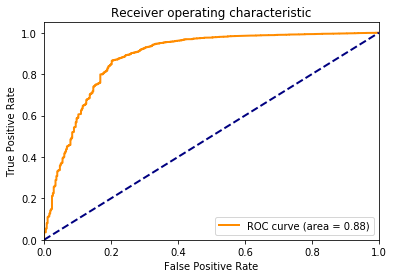

In [54]:
eval_pool = Pool(X_validation, y_validation, cat_features=cat_features)
curve = get_roc_curve(model, eval_pool)
(fpr, tpr, thresholds) = curve

plt.figure()
lw = 2
roc_auc = sklearn.metrics.auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc)

plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

In [55]:
from catboost.utils import get_fpr_curve
from catboost.utils import get_fnr_curve

In [56]:
? get_fpr_curve

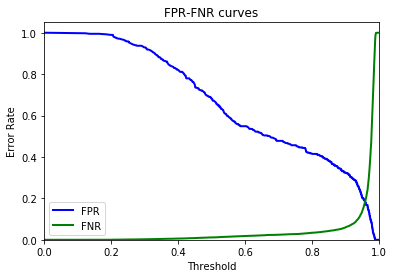

In [57]:
plt.figure()
lw = 2
(thresholds, fpr) = get_fpr_curve(curve=curve)
(thresholds, fnr) = get_fnr_curve(curve=curve)
plt.plot(thresholds, fpr, color='blue', lw=lw, label='FPR')
plt.plot(thresholds, fnr, color='green', lw=lw, label='FNR')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Threshold')
plt.ylabel('Error Rate')
plt.title('FPR-FNR curves')
plt.legend(loc="lower left")
plt.show()

In [58]:
from catboost.utils import select_threshold

print(select_threshold(model=model, data=eval_pool, FNR=0.01))
print(select_threshold(model=model, data=eval_pool, FPR=0.01))

0.4719014981770065
0.9876472944285266


## Snapshotting

In [59]:
#!rm 'catboost_info/snapshot.bkp'



In [60]:
#!rm 'catboost_info/snapshot.bkp'
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=20,
    save_snapshot=True,
    snapshot_file='snapshot.bkp',
    snapshot_interval=1,
    random_seed=43
)
model.fit(
    X_train, y_train,
    eval_set=(X_validation, y_validation),
    cat_features=cat_features,
    verbose=True
)

0:	learn: 0.3019732	test: 0.3022828	best: 0.3022828 (0)	total: 67ms	remaining: 1.27s
1:	learn: 0.2238474	test: 0.2233617	best: 0.2233617 (1)	total: 148ms	remaining: 1.33s
2:	learn: 0.1904507	test: 0.1818139	best: 0.1818139 (2)	total: 252ms	remaining: 1.43s
3:	learn: 0.1802458	test: 0.1659696	best: 0.1659696 (3)	total: 363ms	remaining: 1.45s
4:	learn: 0.1754740	test: 0.1587777	best: 0.1587777 (4)	total: 485ms	remaining: 1.46s
5:	learn: 0.1703625	test: 0.1514527	best: 0.1514527 (5)	total: 566ms	remaining: 1.32s
6:	learn: 0.1684087	test: 0.1485265	best: 0.1485265 (6)	total: 654ms	remaining: 1.22s
7:	learn: 0.1672054	test: 0.1477918	best: 0.1477918 (7)	total: 741ms	remaining: 1.11s
8:	learn: 0.1662518	test: 0.1470028	best: 0.1470028 (8)	total: 842ms	remaining: 1.03s
9:	learn: 0.1656720	test: 0.1469340	best: 0.1469340 (9)	total: 929ms	remaining: 929ms
10:	learn: 0.1646958	test: 0.1458786	best: 0.1458786 (10)	total: 1.02s	remaining: 832ms
11:	learn: 0.1639292	test: 0.1456439	best: 0.1456439 

In [61]:
model = CatBoostClassifier(
    iterations=200,
    save_snapshot=True,
    snapshot_file='snapshot.bkp',
    snapshot_interval=1,
    random_seed=43
)
model.fit(
    X_train, y_train,
    eval_set=(X_validation, y_validation),
    cat_features=cat_features,
    verbose=True,
    plot=True
)

20:	learn: 0.1607445	test: 0.1440626	best: 0.1440626 (20)	total: 1.82s	remaining: 17.1s
21:	learn: 0.1606770	test: 0.1439965	best: 0.1439965 (21)	total: 1.9s	remaining: 15.8s
22:	learn: 0.1606616	test: 0.1440083	best: 0.1439965 (21)	total: 1.97s	remaining: 14.8s
23:	learn: 0.1606540	test: 0.1440366	best: 0.1439965 (21)	total: 2.04s	remaining: 14s
24:	learn: 0.1606450	test: 0.1440838	best: 0.1439965 (21)	total: 2.11s	remaining: 13.6s
25:	learn: 0.1604540	test: 0.1439186	best: 0.1439186 (25)	total: 2.22s	remaining: 14.3s
26:	learn: 0.1600134	test: 0.1436727	best: 0.1436727 (26)	total: 2.33s	remaining: 15s
27:	learn: 0.1600132	test: 0.1436712	best: 0.1436712 (27)	total: 2.4s	remaining: 14.5s
28:	learn: 0.1597968	test: 0.1437510	best: 0.1436712 (27)	total: 2.49s	remaining: 14.6s
29:	learn: 0.1597306	test: 0.1437718	best: 0.1436712 (27)	total: 2.62s	remaining: 15.3s
30:	learn: 0.1595170	test: 0.1437298	best: 0.1436712 (27)	total: 2.77s	remaining: 16.1s
31:	learn: 0.1593775	test: 0.1439295	b

114:	learn: 0.1506871	test: 0.1423714	best: 0.1411666 (78)	total: 10.1s	remaining: 7.52s
115:	learn: 0.1506365	test: 0.1423830	best: 0.1411666 (78)	total: 10.2s	remaining: 7.43s
116:	learn: 0.1505736	test: 0.1425609	best: 0.1411666 (78)	total: 10.3s	remaining: 7.35s
117:	learn: 0.1505321	test: 0.1425929	best: 0.1411666 (78)	total: 10.4s	remaining: 7.29s
118:	learn: 0.1505028	test: 0.1425452	best: 0.1411666 (78)	total: 10.5s	remaining: 7.21s
119:	learn: 0.1497712	test: 0.1424179	best: 0.1411666 (78)	total: 10.7s	remaining: 7.17s
120:	learn: 0.1497006	test: 0.1423512	best: 0.1411666 (78)	total: 10.8s	remaining: 7.11s
121:	learn: 0.1496638	test: 0.1423660	best: 0.1411666 (78)	total: 11s	remaining: 7.1s
122:	learn: 0.1496092	test: 0.1423799	best: 0.1411666 (78)	total: 11.1s	remaining: 7.04s
123:	learn: 0.1495761	test: 0.1422939	best: 0.1411666 (78)	total: 11.2s	remaining: 6.95s
124:	learn: 0.1495648	test: 0.1423047	best: 0.1411666 (78)	total: 11.3s	remaining: 6.86s
125:	learn: 0.1493551	te

## Model predictions

In [62]:
? model.predict_proba

In [63]:
print(model.predict_proba(X=X_validation))

[[0.0688 0.9312]
 [0.008  0.992 ]
 [0.0068 0.9932]
 ...
 [0.0129 0.9871]
 [0.0184 0.9816]
 [0.0273 0.9727]]


In [64]:
print(model.predict(data=X_validation))

[1. 1. 1. ... 1. 1. 1.]


In [65]:
raw_pred = model.predict(data=X_validation, prediction_type='RawFormulaVal')
print(raw_pred)

[2.6056 4.8177 4.9809 ... 4.3367 3.9791 3.5714]


In [66]:
import math
def sigmoid(x):
  return 1 / (1 + math.exp(-x))
probabilities = [sigmoid(x) for x in raw_pred]
print(np.array(probabilities))

[0.9312 0.992  0.9932 ... 0.9871 0.9816 0.9727]


In [67]:
X_prepared = X_validation.values.astype(str).astype(object)
# For FeaturesData class categorial features must have type str

fast_predictions = model.predict_proba(X=FeaturesData(cat_feature_data=X_prepared, 
                                                         cat_feature_names=list(X_validation)))

print(fast_predictions)

[[0.0688 0.9312]
 [0.008  0.992 ]
 [0.0068 0.9932]
 ...
 [0.0129 0.9871]
 [0.0184 0.9816]
 [0.0273 0.9727]]


## Staged prediction

In [68]:
predictions_gen = model.staged_predict_proba(data=X_validation, ntree_start=2, ntree_end=8, eval_period=2)
for iteration, predictions in enumerate(predictions_gen):
    print('Iteration ' + str(iteration) + ', predictions:')
    print(predictions)

Iteration 0, predictions:
[[0.3065 0.6935]
 [0.2317 0.7683]
 [0.2317 0.7683]
 ...
 [0.2317 0.7683]
 [0.2317 0.7683]
 [0.2746 0.7254]]
Iteration 1, predictions:
[[0.3002 0.6998]
 [0.1762 0.8238]
 [0.1422 0.8578]
 ...
 [0.1422 0.8578]
 [0.1916 0.8084]
 [0.2116 0.7884]]
Iteration 2, predictions:
[[0.3307 0.6693]
 [0.13   0.87  ]
 [0.1038 0.8962]
 ...
 [0.1454 0.8546]
 [0.1956 0.8044]
 [0.1938 0.8062]]


## Solving MultiClassification problem

In [69]:
from catboost import CatBoostClassifier
model = CatBoostClassifier(
    iterations=150,
    random_seed=43,
    loss_function='MultiClass'
    #loss_function='MultiClassOneVsAll'
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_validation, y_validation),
    verbose=False,
    plot=True
)

## Metric evaluation on a new dataset

In [70]:
model = CatBoostClassifier(
    random_seed=63,
    iterations=200,
    learning_rate=0.03,
)
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    verbose=50
)

0:	learn: 0.6569860	total: 53.2ms	remaining: 10.6s
50:	learn: 0.1950260	total: 3.33s	remaining: 9.74s
100:	learn: 0.1700584	total: 6.72s	remaining: 6.58s
150:	learn: 0.1641016	total: 10.6s	remaining: 3.42s
199:	learn: 0.1604074	total: 14.1s	remaining: 0us


In [71]:
metrics = model.eval_metrics(data=pool1, 
                             metrics=['Logloss','AUC'],
                             ntree_start=0,
                             ntree_end=0, 
                             eval_period=1,
                             plot=True)

In [72]:
print('AUC values:')
print(np.array(metrics['AUC']))

AUC values:
[0.4998 0.538  0.5504 0.5888 0.6503 0.6487 0.6487 0.6601 0.6601 0.6612
 0.6614 0.67   0.6699 0.6697 0.6697 0.6698 0.6698 0.6698 0.6698 0.7265
 0.7338 0.7376 0.7478 0.7478 0.7506 0.7591 0.7642 0.7877 0.8148 0.8265
 0.8353 0.8459 0.8533 0.8564 0.8573 0.8748 0.8874 0.893  0.8948 0.898
 0.9003 0.9052 0.9122 0.9159 0.92   0.9204 0.9209 0.9246 0.9262 0.9266
 0.9279 0.9303 0.9311 0.9312 0.9327 0.9329 0.9337 0.9341 0.9341 0.9349
 0.9354 0.9365 0.9391 0.9411 0.9424 0.9435 0.9446 0.9458 0.9463 0.9471
 0.9478 0.9481 0.9482 0.9483 0.9486 0.9497 0.951  0.9514 0.9515 0.9519
 0.9522 0.9526 0.953  0.9537 0.9543 0.9544 0.9545 0.9548 0.9548 0.9548
 0.9548 0.9548 0.955  0.9551 0.9553 0.9554 0.9557 0.9557 0.9557 0.9557
 0.956  0.9566 0.9566 0.9569 0.9568 0.957  0.9569 0.9572 0.9573 0.9575
 0.9576 0.9576 0.9577 0.958  0.9587 0.9594 0.9595 0.9594 0.9601 0.9609
 0.9609 0.9608 0.9608 0.9612 0.9616 0.9618 0.9622 0.9623 0.9623 0.9625
 0.9625 0.9628 0.9629 0.9629 0.9629 0.963  0.9631 0.9632 0.9635 0.

## Saving the model

In [73]:
my_best_model = CatBoostClassifier(iterations=10)
my_best_model.fit(
    X_train, y_train,
    eval_set=(X_validation, y_validation),
    cat_features=cat_features,
    verbose=False
)

In [74]:
my_best_model.save_model('catboost_model.bin')

In [75]:
my_best_model.load_model('catboost_model.bin')
print(my_best_model.get_params())
print(my_best_model.random_seed_)

{'iterations': 10, 'loss_function': 'Logloss', 'logging_level': 'Silent'}
17379826207872


In [76]:
my_best_model.save_model('catboost_model.json', format='json')

## Feature importances

In [77]:
model = CatBoostClassifier(
    random_seed=63,
    iterations=200,
    learning_rate=0.03)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    verbose=50
)

0:	learn: 0.6569860	total: 56.9ms	remaining: 11.3s
50:	learn: 0.1950260	total: 4.06s	remaining: 11.9s
100:	learn: 0.1700584	total: 7.18s	remaining: 7.04s
150:	learn: 0.1641016	total: 10.8s	remaining: 3.5s
199:	learn: 0.1604074	total: 14.3s	remaining: 0us


In [78]:
fstrs = model.get_feature_importance(prettified=True)

In [79]:
{feature_name : value for  feature_name, value in fstrs}

{b'MGR_ID': 18.398056223683028,
 b'RESOURCE': 21.27625707750949,
 b'ROLE_CODE': 11.943230282191124,
 b'ROLE_DEPTNAME': 15.252806962601875,
 b'ROLE_FAMILY': 2.4789173515872176,
 b'ROLE_FAMILY_DESC': 9.984073192415533,
 b'ROLE_ROLLUP_1': 2.6278918788673633,
 b'ROLE_ROLLUP_2': 13.582536028250486,
 b'ROLE_TITLE': 4.456231002893895}

## Shap values

https://github.com/slundberg/shap

In [80]:
def object_predictions(model, obj):
    print('Probability of class 1 = {:.4f}'.format(model.predict_proba([obj])[0][1]))
    print('Formula raw prediction = {:.4f}'.format(model.predict([obj], prediction_type='RawFormulaVal')[0]))
    

In [81]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(Pool(X, y, cat_features=cat_features))


The model has complex ctrs, so the SHAP values will be calculated approximately.


In [82]:
explainer.expected_value

3.345740996864643

In [83]:
object_predictions(model, X.iloc[3,:])

Probability of class 1 = 0.9798
Formula raw prediction = 3.8820


In [84]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[3,:], X.iloc[3,:])

The above explanation shows features each contributing to push the model output from the base value (the average model output over the training dataset we passed) to the model output. Features pushing the prediction higher are shown in red, those pushing the prediction lower are in blue

In [85]:
object_predictions(model, X.iloc[91,:])

Probability of class 1 = 0.6404
Formula raw prediction = 0.5772


In [86]:
import shap
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[91,:], X.iloc[91,:])

To get an overview of which features are most important for a model we can plot the SHAP values of every feature for every sample. The plot below sorts features by the sum of SHAP value magnitudes over all samples, and uses SHAP values to show the distribution of the impacts each feature has on the model output. The color represents the feature value (red high, blue low).

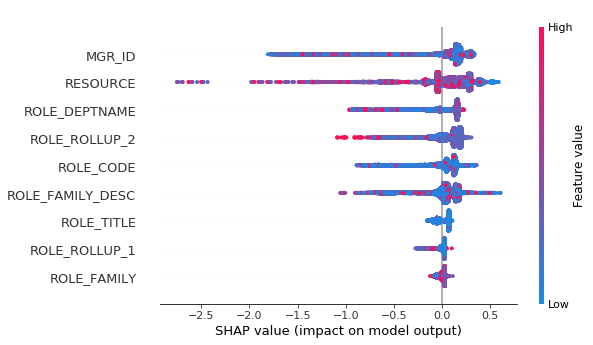

In [87]:
shap.summary_plot(shap_values, X)

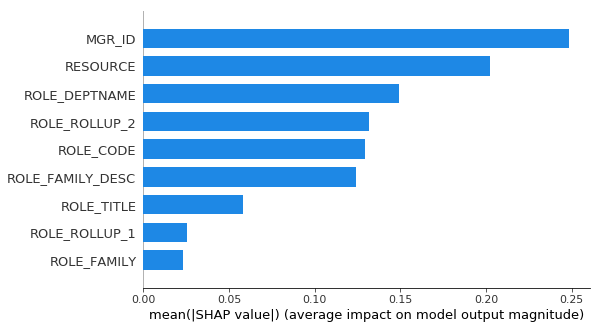

In [88]:
shap.summary_plot(shap_values, X, plot_type="bar")

## Hyperparameter tunning

### Training speed

In [89]:
from catboost import CatBoost
fast_model = CatBoostClassifier(
    random_seed=63,
    iterations=150,
    learning_rate=0.01,
    boosting_type='Plain',
    bootstrap_type='Bernoulli',
    subsample=0.5,
    rsm=0.5,
     one_hot_max_size=20,
    leaf_estimation_iterations=2,
    max_ctr_complexity=1)

fast_model.fit(
    X_train, y_train,
    cat_features=cat_features,
    verbose=False,
    plot=True
)

### Accuracy

In [90]:
tunned_model = CatBoostClassifier(
    random_seed=63,
    iterations=1000,
    learning_rate=0.03,
    l2_leaf_reg=3,
    bagging_temperature=1,
    random_strength=1,
    one_hot_max_size=2,
    leaf_estimation_method='Newton'
)
tunned_model.fit(
    X_train, y_train,
    cat_features=cat_features,
    verbose=False,
    eval_set=(X_validation, y_validation),
    plot=True
)

## Training the model after parameter tunning

In [91]:
best_model = CatBoostClassifier(
    random_seed=63,
    iterations=int(tunned_model.tree_count_ * 1.2),
)
best_model.fit(
    X, y,
    cat_features=cat_features,
    verbose=100
)

0:	learn: 0.6431867	total: 103ms	remaining: 1m 51s
100:	learn: 0.1590533	total: 8.58s	remaining: 1m 23s
200:	learn: 0.1517316	total: 16.1s	remaining: 1m 10s
300:	learn: 0.1487795	total: 23.5s	remaining: 1m
400:	learn: 0.1468414	total: 31.3s	remaining: 53.2s
500:	learn: 0.1448880	total: 39.4s	remaining: 45.7s
600:	learn: 0.1433889	total: 48.4s	remaining: 38.8s
700:	learn: 0.1421200	total: 58.1s	remaining: 31.7s
800:	learn: 0.1411938	total: 1m 6s	remaining: 23.4s
900:	learn: 0.1401819	total: 1m 15s	remaining: 15.2s
1000:	learn: 0.1394250	total: 1m 25s	remaining: 6.99s
1082:	learn: 0.1388355	total: 1m 32s	remaining: 0us


## Calculate predictions for the contest

In [92]:
X_test = test_df.drop('id', axis=1)
test_pool = Pool(data=X_test, cat_features=cat_features)
contest_predictions = best_model.predict_proba(test_pool)
print('Predictoins:')
print(contest_predictions)

Predictoins:
[[0.4024 0.5976]
 [0.015  0.985 ]
 [0.0101 0.9899]
 ...
 [0.0089 0.9911]
 [0.0496 0.9504]
 [0.0135 0.9865]]


## Prepare the submission

In [93]:
f = open('submit.csv', 'w')
f.write('Id,Action\n')
for idx in range(len(contest_predictions)):
    line = str(test_df['id'][idx]) + ',' + str(contest_predictions[idx][1]) + '\n'
    f.write(line)
f.close()

Submit your solution [here](https://www.kaggle.com/c/amazon-employee-access-challenge/submit).
Good luck!!!